# Measurements

A QPSK link from bits to bits, measured with probes: spectrum, eye,
constellation, SNR, power and bit errors. The numbers are checked against
theory, and the same probes then drive a live dashboard.

In [1]:
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np
from scipy.special import erfc

import sigline as sl

sps, Rs = 8, 1000.0  # samples per symbol, symbol rate / Hz
fs = sps * Rs
esn0_db = 10.0  # Es/N0 at the decision
n_sym = 50_000

## The link

Gray-mapped QPSK, zero-stuffed by `sps`, shaped by a root-raised-cosine
`FIR`; complex noise added; matched filter; one sample per symbol; bits.
Multirate blocks come later, so two small blocks change the rate here.

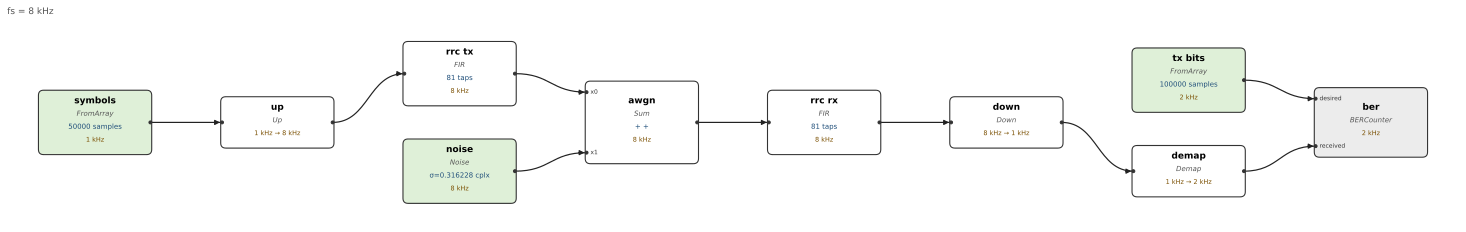

In [2]:
def rrc(beta, sps, span):
    # root-raised-cosine impulse response, closed form, unit energy
    t = np.arange(-span * sps // 2, span * sps // 2 + 1) / sps
    with np.errstate(divide="ignore", invalid="ignore"):
        h = (
            np.sin(np.pi * t * (1 - beta))
            + 4 * beta * t * np.cos(np.pi * t * (1 + beta))
        ) / (np.pi * t * (1 - (4 * beta * t) ** 2))
    h[t == 0] = 1 - beta + 4 * beta / np.pi
    edge = np.isclose(np.abs(t), 1 / (4 * beta))
    a = np.pi / (4 * beta)
    h[edge] = (
        beta / np.sqrt(2) * ((1 + 2 / np.pi) * np.sin(a) + (1 - 2 / np.pi) * np.cos(a))
    )
    return h / np.sqrt(np.sum(h**2))


class Up(sl.Block):
    resampling_ratio = Fraction(sps)

    def step(self, x):
        y = np.zeros(len(x) * sps, dtype=x.dtype)
        y[::sps] = x
        return y


class Down(sl.Block):
    resampling_ratio = Fraction(1, sps)

    def step(self, x):
        return x[::sps]


class Demap(sl.Block):
    resampling_ratio = Fraction(2)  # one symbol -> two bits

    def step(self, x):
        b = np.empty(2 * len(x))
        b[0::2], b[1::2] = x.real < 0, x.imag < 0
        return b


rng = np.random.default_rng(1)
bits = rng.integers(0, 2, 2 * n_sym)
symbols = ((1 - 2 * bits[0::2]) + 1j * (1 - 2 * bits[1::2])) / np.sqrt(2)
taps = rrc(0.35, sps, 10)

tx_bits = sl.FromArray(bits.astype(float), fs=2 * Rs, name="tx bits")
tx, up, shape = (
    sl.FromArray(symbols, fs=Rs, name="symbols"),
    Up(name="up"),
    sl.FIR(taps, name="rrc tx"),
)
add, mf, down, demap = (
    sl.Sum(name="awgn"),
    sl.FIR(taps, name="rrc rx"),
    Down(name="down"),
    Demap(name="demap"),
)
ber = sl.BERCounter(sync=500, name="ber")
tx >> up >> shape >> add["x0"]
sl.Noise(10 ** (-esn0_db / 20), seed=2, complex=True, name="noise") >> add["x1"]
add >> mf >> down >> demap >> ber["received"]
tx_bits >> ber["desired"]

d = sl.Diagram(ber, fs=fs)
d

## Probes

Measurements attach to any signal without changing the diagram.

In [3]:
QPSK = np.array([1 + 1j, -1 + 1j, -1 - 1j, 1 - 1j]) / np.sqrt(2)
spec = d.probe("rrc tx", sink=sl.SpectrumAnalyzer(nfft=1024, label="tx"))
eye = d.probe("rrc rx", sink=sl.EyeDiagram(sps, offset=0, label="matched filter"))
const = d.probe(
    "down", sink=sl.ConstellationScope(QPSK, keep=2000, skip=20, label="rx")
)
snr = d.probe("down", sink=sl.SNREstimator("dd", constellation=QPSK, skip=20))
power = d.probe("rrc tx", sink=sl.PowerMeter(interval=5.0))

d.run(n=n_sym * sps, chunk=4096)
print(ber.summary())

ber: BER 6.263e-04 (62/99000 bits), 95% CI [4.80e-04, 8.03e-04], delay 20 bits


## Against theory

With unit-energy pulses the decision sees $E_s/N_0$ directly. Gray QPSK has
$\mathrm{BER} = \tfrac12 \operatorname{erfc}\sqrt{E_b/N_0}$ with
$E_b = E_s/2$; MER and decision-directed SNR equal $E_s/N_0$; the transmit
power per sample is $1/\text{sps}$.

In [4]:
ebn0 = 10 ** (esn0_db / 10) / 2
lo, hi = ber.confidence()
theory = 0.5 * erfc(np.sqrt(ebn0))
print(f"BER    {ber.ber:.2e}  theory {theory:.2e}  95% CI [{lo:.2e}, {hi:.2e}]")
print(f"MER    {const.mer_db:.2f} dB  theory {esn0_db:.2f} dB")
print(f"SNR dd {snr.snr_db:.2f} dB")
print(f"power  {power.level:.2f} dB  theory {10 * np.log10(1 / sps):.2f} dB")

BER    6.26e-04  theory 7.83e-04  95% CI [4.80e-04, 8.03e-04]
MER    10.03 dB  theory 10.00 dB
SNR dd 10.03 dB
power  -9.03 dB  theory -9.03 dB


## A dashboard

Every measurement plots into any matplotlib axes, so they compose freely.

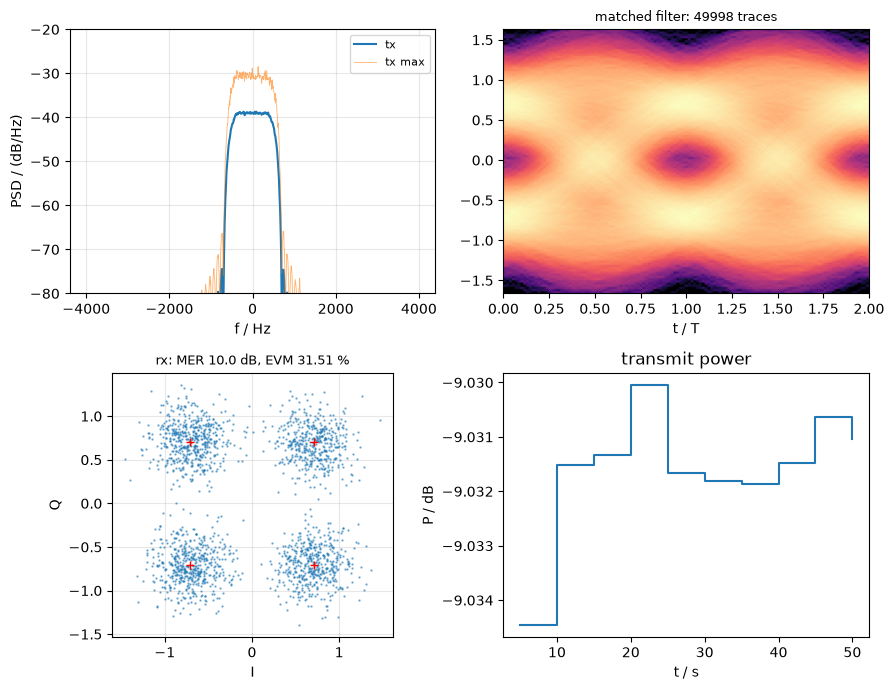

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(9, 7))
spec.plot(ax=ax[0, 0])
ax[0, 0].set_ylim(-80, -20)
eye.plot(ax=ax[0, 1])
const.plot(ax=ax[1, 0])
t = power.readings_t
ax[1, 1].step(t, power.readings, where="post")
ax[1, 1].set(xlabel="t / s", ylabel="P / dB", title="transmit power")
fig.tight_layout()
plt.show()

## Live

The same probes on a running diagram: a looping source, an exponentially
averaged spectrum, and `sl.watch` redrawing two panels.

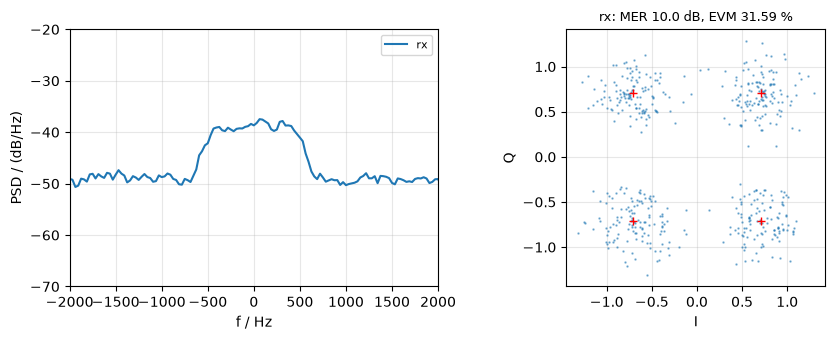

ber: BER 6.000e-04 (3/5000 bits), 95% CI [1.24e-04, 1.75e-03], delay 20 bits


In [6]:
tx.loop = tx_bits.loop = True
d.remove_probe(spec)
spec = d.probe(
    "awgn", sink=sl.SpectrumAnalyzer(nfft=256, average="exp", alpha=0.05, label="rx")
)
const.keep = 500


def draw(fig):
    a1, a2 = fig.subplots(1, 2)
    spec.plot(ax=a1, max_hold=False)
    a1.set_ylim(-70, -20)
    a1.set_xlim(-2000, 2000)
    const.plot(ax=a2)
    fig.tight_layout()


d.reset()
d.start(3.0, chunk=1024)
fig = sl.watch(d, draw, interval=0.3, figsize=(9, 3.5))
print(ber.summary())

## Summary

- `SpectrumAnalyzer`, `PowerMeter`, `ConstellationScope`, `EyeDiagram`,
  `SNREstimator`, `BERCounter`: blocks or probes (`d.probe(..., sink=...)`).
- Results match theory: BER, MER, SNR, power.
- Each `.plot(ax=...)` composes into any figure, also live with `sl.watch`.